# Sales forecast: next 3 months of won revenue

**Data:** LeadPilot's own won deals, summed per month (run `seed_demo` first for demo data).
**Candidates:** linear regression on lag-1/2/3 + trend + month-of-year seasonality, a smaller
trend + seasonality regression, a ridge (regularized) regression, and two baselines (naive and
3-month moving average), all scored in a **rolling-origin backtest** (each month predicted
only from earlier months: no peeking into the future).

In [1]:
import os, sys, warnings
from pathlib import Path

BACKEND = Path.cwd().resolve().parents[1]  # backend/ml/notebooks -> backend
sys.path.insert(0, str(BACKEND))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE = "#2a78d6"

In [2]:
# The forecast uses our own CRM data, so this notebook boots Django (SQLite/Postgres per .env).
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings.dev")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"  # Jupyter runs an event loop
import django
django.setup()

In [3]:
from django.utils import timezone
from ml import services
from ml.pipelines import forecast
closed = services._won_deals(None)
series = forecast.monthly_series(closed, end=pd.Timestamp(timezone.now()))
print(len(closed), "won deals over", len(series), "months")
series.tail(6).to_frame("revenue")

213 won deals over 23 months


,revenue
2026-06,7810000.0
2026-07,3300000.0
2026-08,5190000.0
2026-09,12810000.0
2026-10,19310000.0
2026-11,15955000.0


## 1. EDA

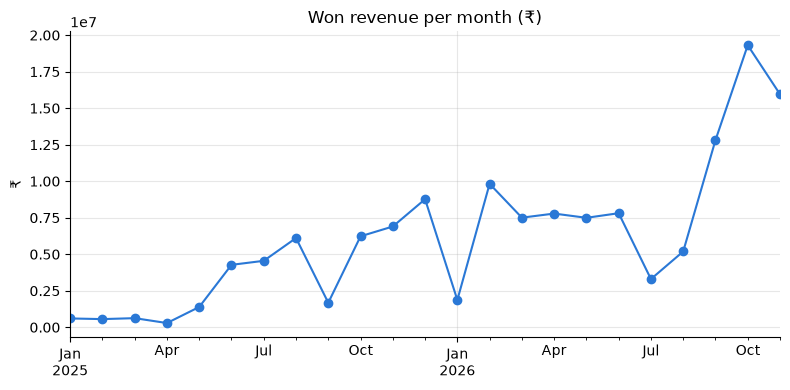

In [4]:
ax = series.plot(marker="o", color=BLUE, title="Won revenue per month (₹)")
ax.set_ylabel("₹"); plt.tight_layout()

## 2. Features: lags, trend, seasonality

In [5]:
forecast.design(series).tail(5).round(2)

,y,lag1,lag2,lag3,t,sin,cos
2026-07,3300000.0,7810000.0,7495000.0,7785000.0,18,-0.50,-0.87
2026-08,5190000.0,3300000.0,7810000.0,7495000.0,19,-0.87,-0.50
2026-09,12810000.0,5190000.0,3300000.0,7810000.0,20,-1.00,-0.00
2026-10,19310000.0,12810000.0,5190000.0,3300000.0,21,-0.87,0.50
2026-11,15955000.0,19310000.0,12810000.0,5190000.0,22,-0.50,0.87


## 3. Rolling-origin backtest (last 6 months)

,method,mae,rmse,r2
0,naive,3008333.0,3959568.0,0.0
1,trend_seasonal_regression,3692447.0,4460398.0,0.0
2,ridge_regression,3369125.0,4619070.0,0.0
3,moving_average,3519444.0,5157907.0,-0.0
4,linear_regression,3855665.0,5728486.0,-0.0


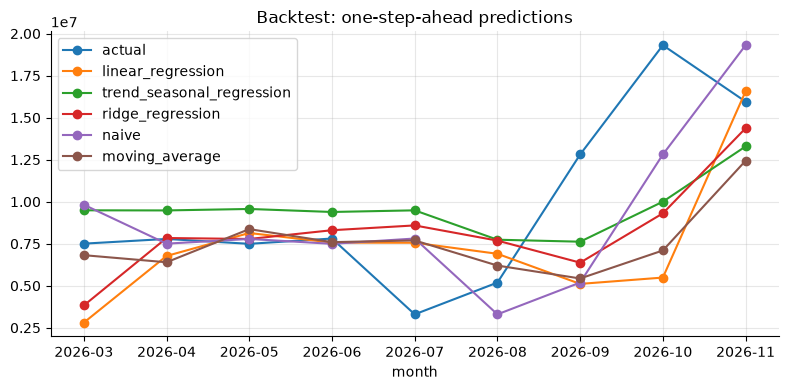

In [6]:
bt = forecast.backtest(series)
methods = forecast.score_methods(bt)
display(methods.round(0))
ax = bt.set_index("month")[["actual", *forecast.METHODS]].plot(marker="o")
ax.set_title("Backtest: one-step-ahead predictions"); plt.tight_layout()

**Final choice:** the method with the lowest backtest RMSE makes the forecast (first row
above). With only ~2 years of noisy monthly data, a simple baseline can beat the regressions:
the full lag model has 6 parameters for ~15 training rows and overfits. We report that honestly
instead of forcing the regression; as history grows, the trend/seasonality regressions get
more rows and the same selection rule will pick them when they genuinely win.
The band is ±1.96 × the chosen method's backtest RMSE (≈95% if errors are roughly normal),
widening by √h.

## 4. Forecast

Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


,forecast,lower,upper
month,,,
2026-12,15955000.0,8194248.0,23715752.0
2027-01,15955000.0,4979639.0,26930361.0
2027-02,15955000.0,2512983.0,29397017.0


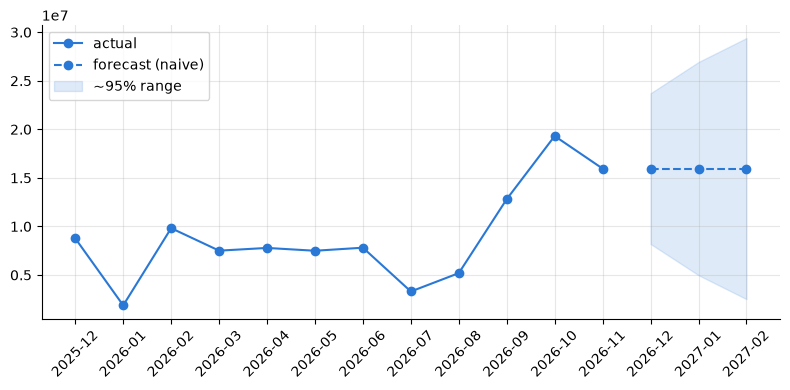

In [7]:
result = forecast.forecast(series)
fc = pd.DataFrame(result["forecast"]).set_index("month")
hist = series.iloc[-12:]
ax = plt.gca()
ax.plot([str(p) for p in hist.index], hist.values, marker="o", color=BLUE, label="actual")
ax.plot(fc.index, fc["forecast"], marker="o", linestyle="--", color=BLUE, label=f"forecast ({result['chosen']})")
ax.fill_between(fc.index, fc["lower"], fc["upper"], color=BLUE, alpha=0.15, label="~95% range")
ax.legend(); plt.xticks(rotation=45); plt.tight_layout()
fc.round(0)

In [8]:
metrics = forecast.train(closed, save=True)
{k: metrics.get(k) for k in ("chosen_model", "rows")} | metrics.get("test", {})

Saved forecast.joblib (naive)


{'chosen_model': 'naive',
 'rows': 23,
 'mae': 3008333.3333,
 'rmse': 3959567.5269,
 'r2': 0.3568}